In [1]:
from mt_rent_statement import *

### Load data

In [2]:
start='2025-09-01'
end='2025-09-30'
dfT=load_tenancies('all_tenancies.xls')
dfAll=load_data(start,end)
dfAll.head(3)

Reading file: C:\Work\Mat\property\data\property\checked\SEP2025_codedAndCategorised.xlsx


,Account,Amount,Subcategory,Memo,Property,Description,Cat,Subcat
2025-09-01,20-74-09 60458872,-3.56,Contactless Card Purchase,MINI MARKET EVA PA GREECEAMOUNT IN EUR4,NaN,NaN,PersonalExpense,Holiday
2025-09-01,60-83-71 00558156,925.00,REVENUE,R Cowie FLAT 14. PO4 0RF,F141214ALH,NaN,OurRent,NaN
2025-09-01,60-83-71 00558156,775.00,REVENUE,Nicole Byrne FL7 ALHAMBRA RD,F71618ALH,NaN,OurRent,NaN


### Rent Statement

In [3]:
paidinadvancelist = ['Mr Kaung Myat Thu (30/06/2025)']
inarrearslist = []
dfRs=get_rent_statement(dfAll, dfT, start, end, inarrearslist, paidinadvancelist)
dfRs=dfRs.round(0)
#dfRs.sort_values(by=['Net'], ascending=False).style.apply(custom_style, axis=1)
#dfRs.sort_values(by=['Bills'], ascending=True).style.apply(custom_style, axis=1)
#dfRs.style.apply(custom_style, axis=1)
num_cols = dfRs.select_dtypes(include=["number"]).columns
dfRs.style.format({c: "{:.0f}" for c in num_cols}).apply(custom_style, axis=1)

,Tenant,Agent,Received,Bills,Mortgage,Net,Status
Property,,,,,,,
321 London Rd,,,0,0,0,0,
Flat 1 - 321 London Rd,Ruksana Akter Chowdhury (09/08/2023),0,775,0,-410,365,Paid
Flat 2 - 321 London Rd,Thomas Montgomery (08/03/2024-07/02/2026),0,775,0,-392,383,Paid
Flat 3 - 321 London Rd,Sean Connacher and Pete Davies (31/10/2024-31/03/2026),0,1575,0,-331,1244,Paid
Flat 4 - 321 London Rd,Chloe Freshney & Harry Aldingtons (31/01/2023),0,800,0,-410,390,Paid
169 Fawcett Rd,,,0,-46,0,-46,
Flat 1 - 169 Fawcett Rd,Since 30/07/2025,,0,-458,-369,-827,Empty
Flat 2 - 169 Fawcett Rd,Matthew Granil (31/07/2024),0,775,0,-329,446,Paid
Flat 3 - 169 Fawcett Rd,Mr William Sait (30/06/2025-27/07/2026),0,825,0,-394,431,Paid


Notes:

Remarks:
- each 0.25% increase in rates causes an increase in costs of £750 - ideally we need rates back at 4.5% to pay £22500 p/m
- find out what happens when a business loans money to another and it is not repaid - ask Chatgpt
- things should improve in March - by then hopefully empties rented, paid in advance start to pay again in March


### Income/Expenditure per Property

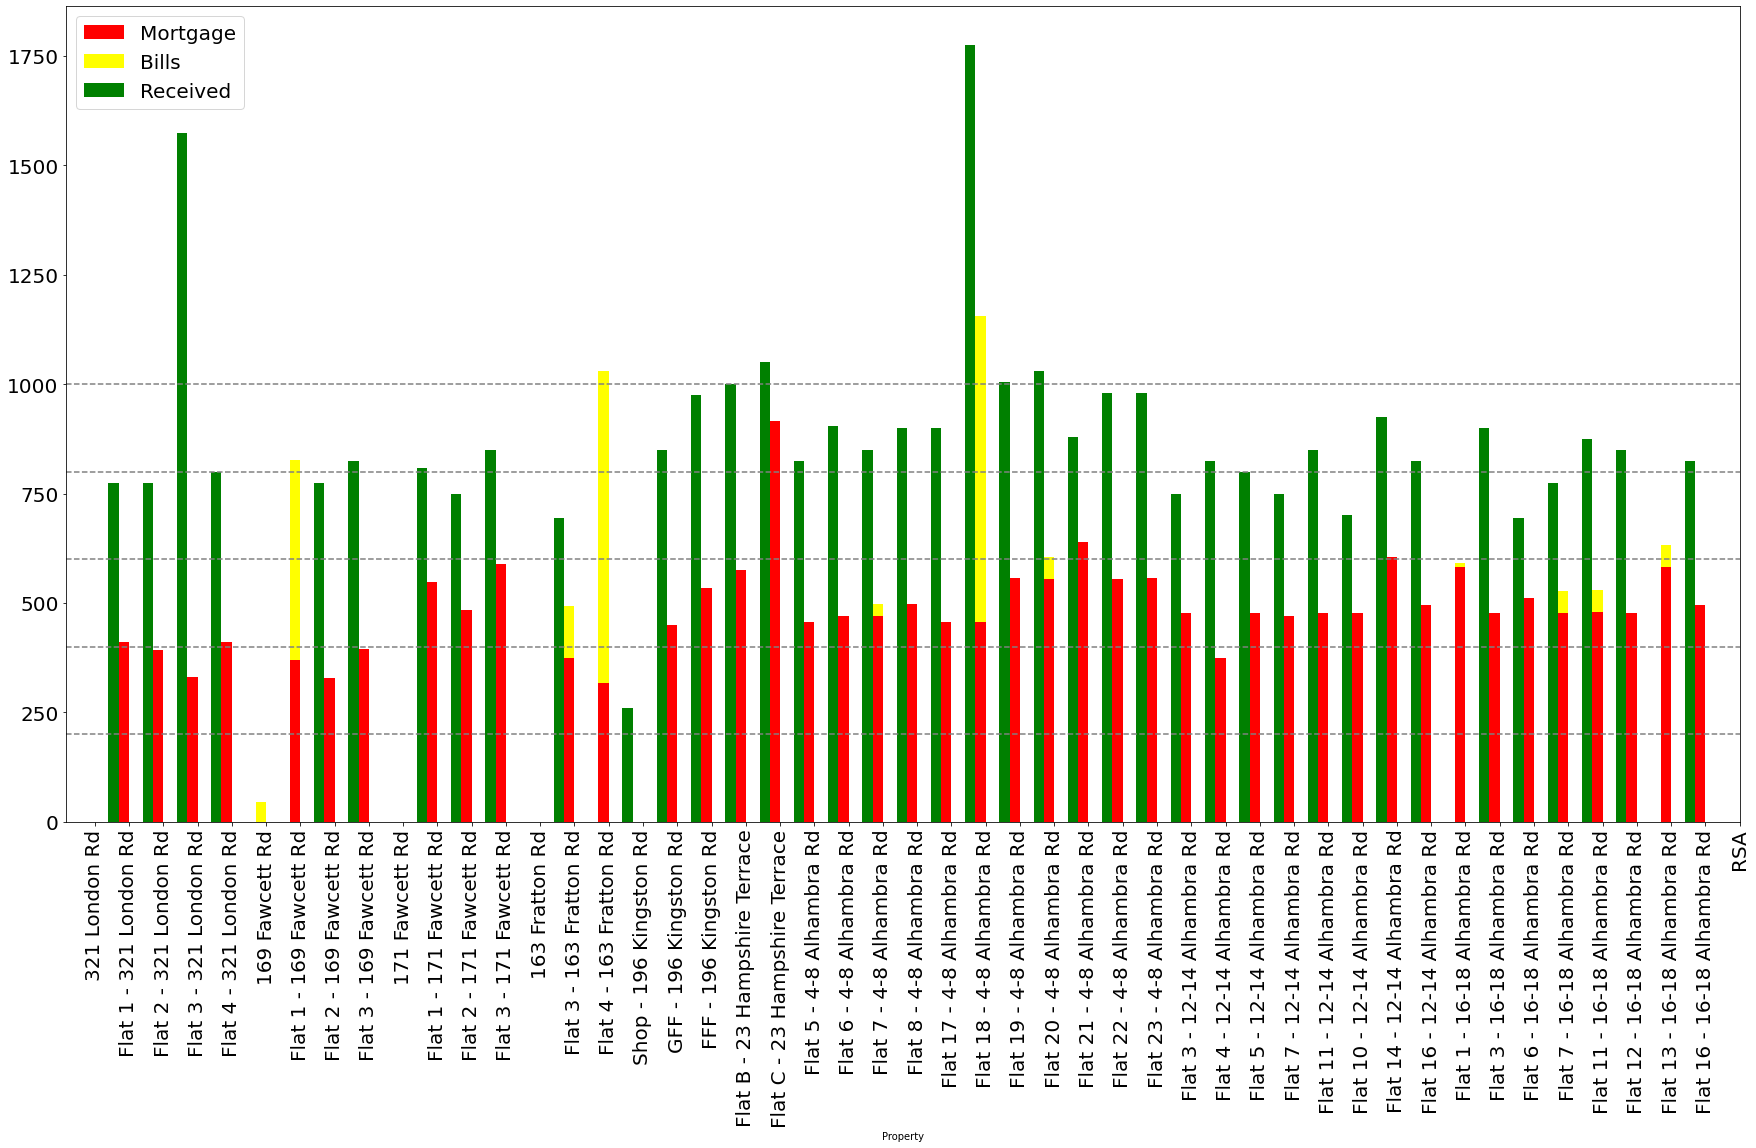

In [4]:
plot_income_expenditure_per_property(dfRs[:-1])

### Net Income Per Property

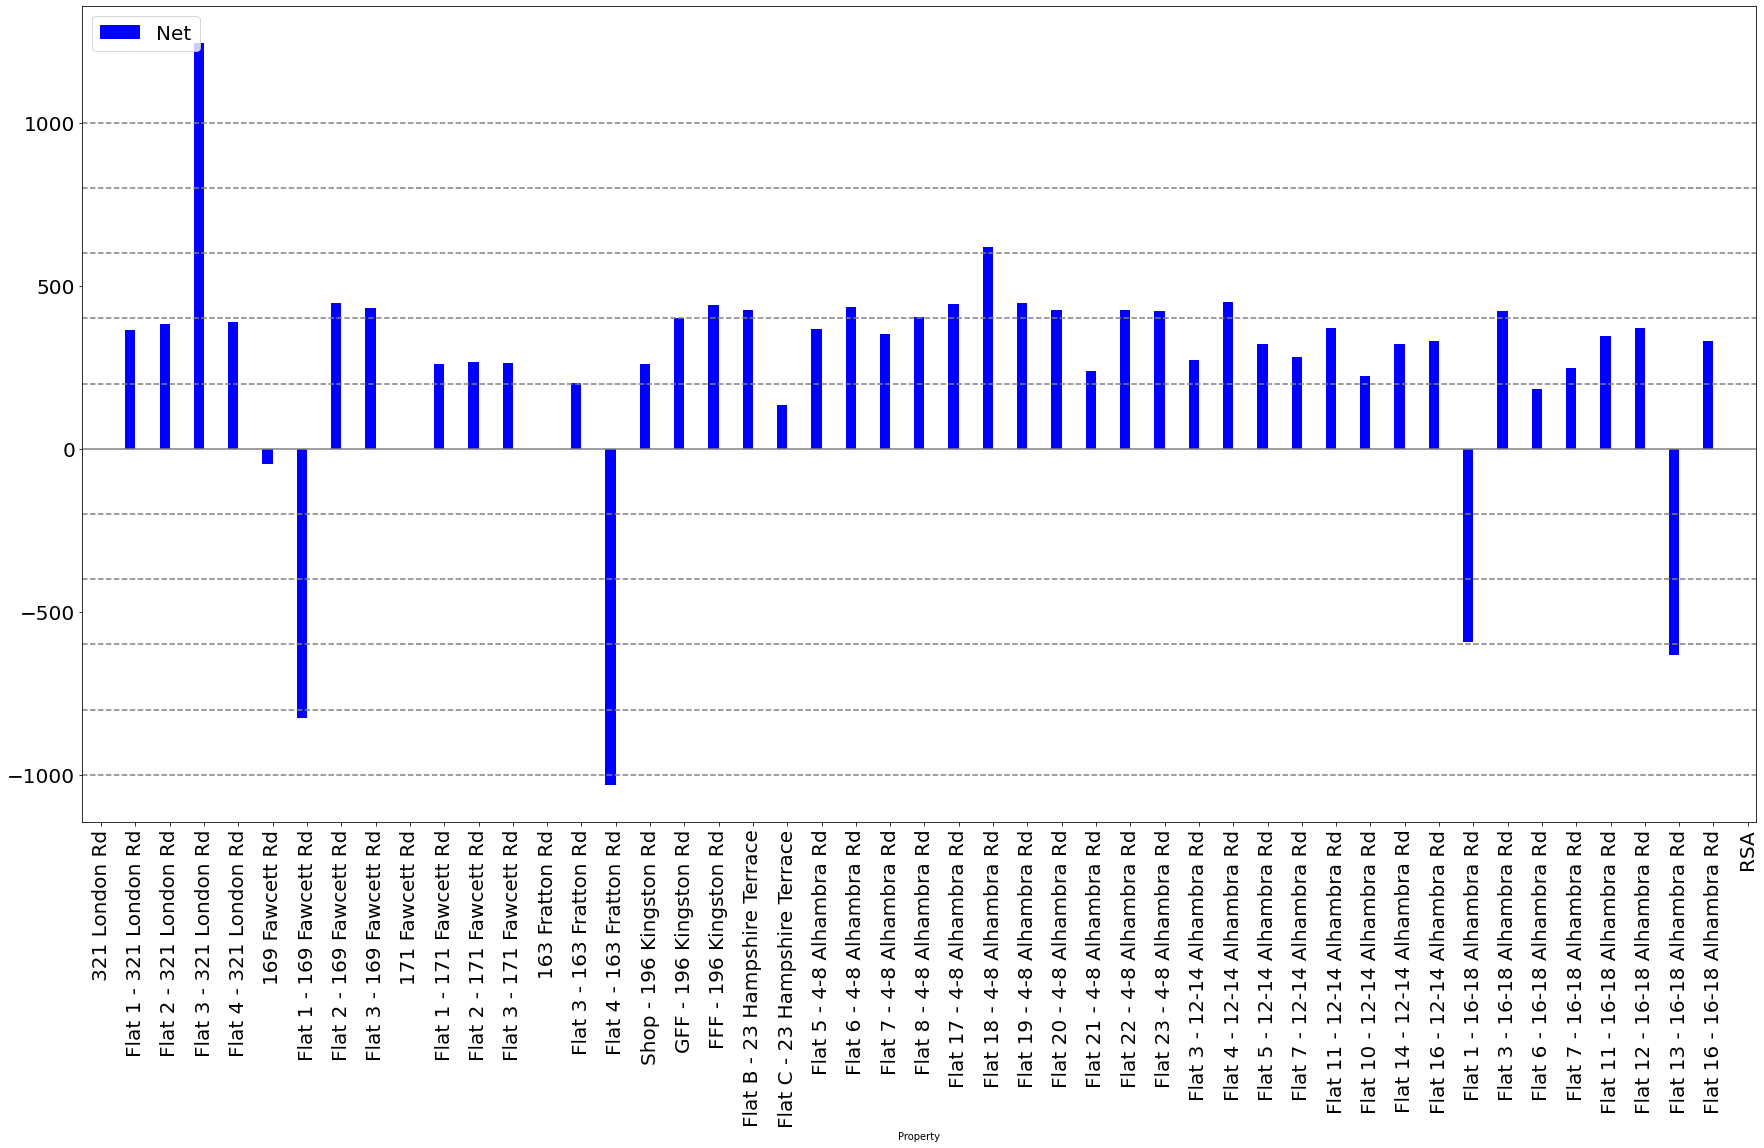

In [5]:
plot_net_income(dfRs[:-1])

### Personal Expenses


Total PersonalExpense: £6,382.02


<AxesSubplot:title={'center':'PersonalExpense by Subcat (total £6,382)'}>

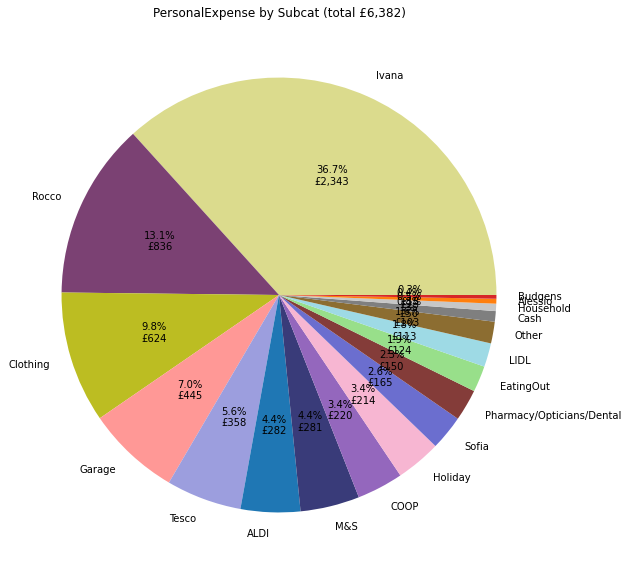

In [17]:
plot_personal_expense_by_subcat(dfAll, start, end)


Notes:
- Ivana Car Insurance £843, £1000 wages

### Accounts Check
Check Drawings against expenses

In [7]:
dfAll[(dfAll.Cat=='RegularPayment')|(dfAll.Cat=='PersonalExpense')|(dfAll.Cat=='Hilltop')|(dfAll.Cat=='HMRCDD')|(dfAll.Cat=='Drawings')|(dfAll.Cat=='SchoolFee')].groupby(['Cat']).sum()

,Amount,Description
Cat,,
Hilltop,-300.00,0.0
PersonalExpense,-6840.52,0.0
RegularPayment,-1611.92,0.0
SchoolFee,-2887.14,0.0


In [8]:
dfAll.groupby(['Account','Cat']).sum().style.apply(custom_style_accounts_cat, axis=1)

#### Mortgage check
Check mortgages refunded from business account

In [9]:
dfMtg=dfAll[((dfAll.Cat=='Mortgage')|(dfAll.Cat=='MortgageRefund'))&(dfAll.Account!='60-83-71 00558156')].groupby(['Account','Cat']).Amount.sum()
dfMtg=dfMtg.reset_index().pivot('Account','Cat')
dfMtg.columns=dfMtg.columns.get_level_values(1)
if('MortgageRefund' not in dfMtg.columns):
    dfMtg['MortgageRefund']=0
dfMtg['Diff']=dfMtg.Mortgage + dfMtg.MortgageRefund
dfMtg

Cat,Mortgage,MortgageRefund,Diff
Account,,,
20-53-97 30728691,-21023.09,0,-21023.09


In [10]:
dfMtg['Diff'].sum()

-21023.090000000004

#### Rent check
Rents going to wrong account

In [11]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='OurRent')]

,Account,Amount,Subcategory,Memo,Property,Description,Cat,Subcat


In [12]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='OurRent')].groupby(['Cat']).sum()

,Amount,Description
Cat,,


#### Property expense check
Property expenses and service charges taken from 3072 or 6045

In [13]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='PropertyExpense')]

,Account,Amount,Subcategory,Memo,Property,Description,Cat,Subcat
2025-09-12,20-74-09 60458872,-15.0,Standing Order,SSE SOUTHERN ELECT 6882766014 STO,169FAW,NaN,PropertyExpense,NaN
2025-09-12,20-74-09 60458872,15.0,Credit,SSE SOUTHERN E 6882766014 REV0001Pa,169FAW,NaN,PropertyExpense,NaN


In [14]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='PropertyExpense')].groupby(['Cat']).sum()

,Amount,Description
Cat,,
PropertyExpense,0.0,0.0


In [15]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='ServiceCharge')]

,Account,Amount,Subcategory,Memo,Property,Description,Cat,Subcat


In [16]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='ServiceCharge')].groupby(['Cat']).sum()

,Amount,Description
Cat,,
